In [ ]:
# In practice dataset will store something like:

# duration_i = observed minutes

# status_i = 1 if unplug seen, 0 if censored

#EV under ToU vs. EV under 2-rates tariffs, potentially enriched with additional out of trial V2G data

# Initialisation

In [ ]:
import polars as pl
import numpy as np

import lifelines as ll
import matplotlib.pyplot as plt

## Functions

In [ ]:
# def calculate_duration(df_flagged):

#     charges = (
#         df_flagged
#         .filter(pl.col("ev_like"))
#         .sort(["household", "ts"])
#     )

#     # detect new episode when gap > 1 hour
#     charges = charges.with_columns(
#         (
#             (pl.col("ts")
#             - pl.col("ts").shift(1).over("household")
#         ).dt.total_minutes()/60).fill_null(1).alias("gap_h")
#     )

#     charges = charges.with_columns(
#         (pl.col("gap_h") > 1).cast(pl.Int8).alias("new_episode")
#     )

#     charges = charges.with_columns(
#         pl.col("new_episode").cum_sum().over("household").alias("episode_id")
#     )

#     episodes = (
#         charges
#         .group_by(["household", "episode_id"])
#         .agg([
#             pl.col("ts").min().alias("start_ts"),
#             (pl.col("ts").max() + pl.duration(minutes=30)).alias("end_ts"),
#         ])
#         .sort(["household", "start_ts"])
#     )

#     return episodes

: 

: 

In [ ]:
def calculate_gaps(episodes):
    gap_times = (
    episodes
    .with_columns(
        pl.col("start_ts").shift(-1).over("household").alias("next_start")
    )
    .filter(pl.col("next_start").is_not_null())
    .with_columns(
        ((pl.col("next_start") - pl.col("end_ts")).dt.total_minutes()/60).alias("gap_hours_till_next_charge")
    )
    .select(["household", "start_ts", "end_ts", "next_start", "gap_hours_till_next_charge"])
    )

    return gap_times

: 

: 

In [ ]:
def gen_df_events(df_flagged):

    charges = (
        df_flagged
        .filter(pl.col("ev_like"))
        .sort(["household", "ts"])
    )

    # detect new episode when gap > 1 hour
    charges = charges.with_columns(
        (
            (pl.col("ts")
            - pl.col("ts").shift(1).over("household")
        ).dt.total_minutes()/60).fill_null(1).alias("gap_h")
    )

    charges = charges.with_columns(
        (pl.col("gap_h") > 1).cast(pl.Int8).alias("new_episode")
    )

    charges = charges.with_columns(
        pl.col("new_episode").cum_sum().over("household").alias("episode_id")
    )

    episodes = (
        charges
        .group_by(["household", "episode_id"])
        .agg([
            pl.col("ts").min().alias("start_ts"),
            (pl.col("ts").max() + pl.duration(minutes=30)).alias("end_ts"),
        ])
        .sort(["household", "start_ts"])
    )

    return episodes

: 

: 

In [ ]:
def plot_client_with_charging(df_flagged: pl.DataFrame, household_name: str):
    d = (
        df_flagged
        .filter(pl.col("household") == household_name)
        .select(["ts", "kwh", "ev_like"])
        .sort("ts")
        .to_pandas()
    )

    fig, ax = plt.subplots(figsize=(12,4))
    ax.plot(d["ts"], d["kwh"], label="Consumption (kWh)")

    # highlight flagged hours
    m = d["ev_like"].astype(bool)
    ax.scatter(d.loc[m, "ts"], d.loc[m, "kwh"], color="red", s=12, label="Charging events")

    ax.set_title(f"Household {household_name}: consumption with EV charging highlighted")
    ax.set_ylabel("kWh per hour")
    ax.legend()
    plt.tight_layout()
    plt.show()


: 

: 

In [ ]:
def clean_df(data: str):
    path = f"../data/{data}ConsolideNEW.csv"
    df = pl.read_csv(path)

    time_col = df.columns[0]  # the unnamed time column (first column)

    df = (
        df.with_columns(
            [
                pl.col(time_col).str.strptime(pl.Datetime, strict=False).alias("ts"),
                pl.exclude(time_col).cast(pl.Float64),
            ]
        )
    ).drop([df.columns[0]])

    df = (
    df.unpivot(index=["ts"])
      .rename({"variable": "household", "value": "kwh"})
      .sort(["household", "ts"])
      .with_columns([
          pl.col("ts")
            .dt.strftime("%w")
            .cast(pl.Int8)
            .is_in([0, 6])
            .cast(pl.Int8)
            .alias("is_weekend"),

          pl.col("ts").dt.month().alias("month"),
      ])
      .with_columns([
          # season
          pl.when(pl.col("month").is_in([12, 1, 2]))
            .then(pl.lit("winter"))
            .when(pl.col("month").is_in([3, 4, 5]))
            .then(pl.lit("spring"))
            .when(pl.col("month").is_in([6, 7, 8]))
            .then(pl.lit("summer"))
            .otherwise(pl.lit("autumn"))
            .alias("season"),

          # time period
          pl.when(pl.col("is_weekend") == 1)
            # WEEKEND
            .then(
                pl.when(pl.col("ts").dt.hour() < 8)
                  .then(pl.lit("offpeak"))
                  .when(pl.col("ts").dt.hour().is_between(16, 20))
                  .then(pl.lit("peak"))
                  .otherwise(pl.lit("mid"))
            )
            # WEEKDAY
            .otherwise(
                pl.when(pl.col("ts").dt.hour() < 8)
                  .then(pl.lit("offpeak"))
                  .otherwise(pl.lit("mid"))
            )
            .alias("time_period"),
      ])
      .drop("month")
)


    return df


: 

: 

# Exploration

In [12]:
df_C = clean_df('controle')
df_I = clean_df('intervention')

In [46]:
df_C.head()

ts,household,kwh,is_weekend,season,time_period
datetime[μs],str,f64,i8,str,str
2025-01-02 00:00:00,"""03efd9cce89d44d9a78d085c240476…",0.157,0,"""winter""","""offpeak"""
2025-01-02 00:30:00,"""03efd9cce89d44d9a78d085c240476…",0.151,0,"""winter""","""offpeak"""
2025-01-02 01:00:00,"""03efd9cce89d44d9a78d085c240476…",0.475,0,"""winter""","""offpeak"""
2025-01-02 01:30:00,"""03efd9cce89d44d9a78d085c240476…",0.14,0,"""winter""","""offpeak"""
2025-01-02 02:00:00,"""03efd9cce89d44d9a78d085c240476…",0.347,0,"""winter""","""offpeak"""


In [14]:
df_C.tail()

ts,household,kwh,is_weekend,season,time_period
datetime[μs],str,f64,i8,str,str
2025-09-01 23:00:00,"""fff1cfde616f1b03a9b23a1d5385bb…",0.184,0,"""autumn""","""mid"""
2025-09-01 23:30:00,"""fff1cfde616f1b03a9b23a1d5385bb…",0.216,0,"""autumn""","""mid"""
2025-09-02 00:00:00,"""fff1cfde616f1b03a9b23a1d5385bb…",0.141,0,"""autumn""","""offpeak"""
2025-09-02 00:30:00,"""fff1cfde616f1b03a9b23a1d5385bb…",0.118,0,"""autumn""","""offpeak"""
2025-09-02 01:00:00,"""fff1cfde616f1b03a9b23a1d5385bb…",null,0,"""autumn""","""offpeak"""


In [15]:
# plt.plot(df_C['eae8994ed159d687f07d77b1d76db092acfec351ecdf15d682d7e93a7a29be16'])
# plt.show()

## Creation of events df

shape: (9_989, 8)
┌─────────────┬────────────┬────────┬─────────────┬─────────────┬───────┬─────────────┬────────────┐
│ household   ┆ is_weekend ┆ season ┆ time_period ┆ ts          ┆ kwh   ┆ ev_threshol ┆ excess_kwh │
│ ---         ┆ ---        ┆ ---    ┆ ---         ┆ ---         ┆ ---   ┆ d           ┆ ---        │
│ str         ┆ i8         ┆ str    ┆ str         ┆ datetime[μs ┆ f64   ┆ ---         ┆ f64        │
│             ┆            ┆        ┆             ┆ ]           ┆       ┆ f64         ┆            │
╞═════════════╪════════════╪════════╪═════════════╪═════════════╪═══════╪═════════════╪════════════╡
│ 03efd9cce89 ┆ 0          ┆ winter ┆ mid         ┆ 2025-01-02  ┆ 1.09  ┆ 1.045       ┆ 0.045      │
│ d44d9a78d08 ┆            ┆        ┆             ┆ 19:30:00    ┆       ┆             ┆            │
│ 5c240476…   ┆            ┆        ┆             ┆             ┆       ┆             ┆            │
│ 03efd9cce89 ┆ 1          ┆ winter ┆ mid         ┆ 2025-01-05  ┆ 3.195 ┆

(array([ 905., 2523.,  828.,  413., 2126., 2717.,  406.,   16.,   37.,
          18.]),
 array([0.011 , 0.7881, 1.5652, 2.3423, 3.1194, 3.8965, 4.6736, 5.4507,
        6.2278, 7.0049, 7.782 ]),
 <BarContainer object of 10 artists>)

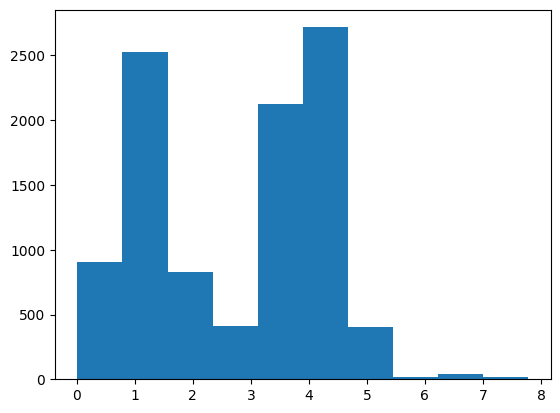

In [48]:
# high quantile method

Q = 0.99                # threshold quantile 

cols = ["household", "is_weekend", "season", 'time_period']

ev_threshold = (
    df_C
    .group_by(cols)
    .agg(pl.col("kwh").quantile(Q, interpolation="nearest").alias("ev_threshold"))  
)

df_flagged_C = (
    df_C
    .join(ev_threshold, on=cols)
    .with_columns([
        (pl.col("kwh") - pl.col("ev_threshold")).clip(lower_bound = 0).alias("excess_kwh"),
    ])
    .with_columns([
        (pl.col("excess_kwh") > 0).alias("ev_like"),
    ])
)


# Just the times to highlight
charge_events = df_flagged_C.filter(pl.col("ev_like")).select(
    cols + ["ts", "kwh", "ev_threshold", "excess_kwh"]
)
print(charge_events)

plt.hist(charge_events['ev_threshold'])

In [51]:
# frequency
freq_events = charge_events.group_by(["household"]).agg([
            pl.col("ts").count().alias("nb_of_events"),
            ((pl.col('ts').max() - pl.col("ts").min()).dt.total_days()/pl.col("ts").count()).alias("freq"),
        ]).sort(["freq", "nb_of_events"])

# plt.plot(b["nb_of_events"])
freq_events

household,nb_of_events,freq
str,u32,f64
"""27b02a005ce819109184d5b5cf1aa1…",115,1.478261
"""a7d9eff41ac5ce1f01dc0bcac33319…",114,1.736842
"""fcc304270f0db2a0b354e816de3b8e…",117,1.786325
"""2ec512b154d1a04ea4d9e31f7dbf44…",117,1.863248
"""85aa9e4bd7cba7b61ae01d85c00b70…",116,1.87069
…,…,…
"""bec6cf422f23b4b85c8c8cb111d4a9…",101,2.287129
"""123c7e64de27fc8e47ced9e8ac651a…",87,2.747126
"""e9841079beed2eea5f907cfa4b90c7…",67,3.059701


In [50]:
# median + charger excess

# Q = 0.5               # baseline quantile 
# CHARGER_KW_OPTIONS = [2.3, 3.6, 7.0]
# TOL = 0.35

# #control
# ##baseline sur energie soutenue 1h 

# cols = ["household", "is_weekend", "season", 'time_period']

# baseline = (
#     df_C
#     .group_by(cols)
#     .agg(pl.col("kwh").quantile(Q, interpolation="nearest").alias("baseline"))  
# )

# df_flagged_C = (
#     df_C
#     .join(baseline, on=cols)
#     .with_columns([
#         (pl.col("kwh") - pl.col("baseline")).clip(lower_bound = 0).alias("excess_kwh"),
#     ])
#     .with_columns([
#         # flag if excess matches any typical charger size (within tolerance)
#         pl.any_horizontal([
#             pl.col("excess_kwh").is_between(kw * (1 - TOL), kw * (1 + TOL)) #--- ev no ev
#             for kw in CHARGER_KW_OPTIONS
#         ]).alias("ev_like"),
#     ])
# )

# # Just the times to highlight
# df_flagged_C.filter(pl.col("ev_like")).select(
#     ["ts", "season", "household", "kwh", "baseline", "excess_kwh", 'time_period']
# )


## EV or no?

(array([ 2., 15.,  8.,  4.,  7., 15., 17., 14.,  6.,  1.]),
 array([0.228 , 0.8538, 1.4796, 2.1054, 2.7312, 3.357 , 3.9828, 4.6086,
        5.2344, 5.8602, 6.486 ]),
 <BarContainer object of 10 artists>)

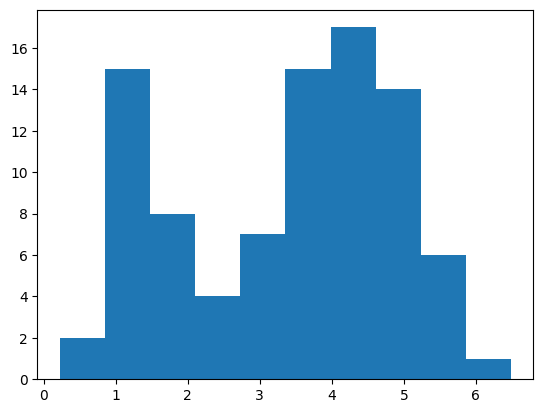

In [ ]:
# gaps between max plateaux?

df = (
    df_C
    .sort("ts")
    .group_by_dynamic(
        index_column="ts",
        every="1mo",
        closed="left",
        group_by="household"
    )
    .agg(
        pl.col("kwh").max().alias("window_max")
    ) ### find all monthly maximum to see if a big jump happens
    .group_by("household")
    .agg([
        (pl.col("window_max").max()-pl.col("window_max").min()).alias("diff_window_max"), ## min of all maximums 
    ])
)

plt.hist(df['diff_window_max'])

In [52]:
#from the graph lets choose to consider a jump from 2.7 wich is reasonable cuz usually CHARGER_KW_OPTIONS = [2.3, 3.6, 7.0]

diff = 2.7

df = (
    df_C
    .sort("ts")
    .group_by_dynamic(
        index_column="ts",
        every="1mo",
        closed="left",
        group_by="household"
    )
    .agg(
        pl.col("kwh").max().alias("window_max")
    )
    .group_by("household")
          
    .agg([pl.col("window_max").max().alias("max_window_max"),
          pl.col("window_max").min().alias("min_window_max"),
        (pl.col("window_max").max()-pl.col("window_max").min()).alias("diff_window_max"),
    ])
)
print(df.filter(pl.col('diff_window_max') > diff))

list_no_ev = (df.filter(pl.col('diff_window_max') > diff)['household'].to_list())

shape: (61, 4)
┌─────────────────────────────────┬────────────────┬────────────────┬─────────────────┐
│ household                       ┆ max_window_max ┆ min_window_max ┆ diff_window_max │
│ ---                             ┆ ---            ┆ ---            ┆ ---             │
│ str                             ┆ f64            ┆ f64            ┆ f64             │
╞═════════════════════════════════╪════════════════╪════════════════╪═════════════════╡
│ 2c8a142ccce0a651aee36edfb604d0… ┆ 5.503          ┆ 1.603          ┆ 3.9             │
│ 5fea815ce393ab5ea54199f3fc1cc4… ┆ 5.949          ┆ 0.81           ┆ 5.139           │
│ 1e22296cafbe2f5fc5167e2415948c… ┆ 4.969          ┆ 1.746          ┆ 3.223           │
│ 7d57ee7f757fed60606f8939ec9826… ┆ 4.319          ┆ 0.851          ┆ 3.468           │
│ 492df8bdb234b2aee443896a039df9… ┆ 4.635          ┆ 0.012          ┆ 4.623           │
│ …                               ┆ …              ┆ …              ┆ …               │
│ 2ec512b154d1a04

In [ ]:
monthly = (
    df_C
    .group_by_dynamic(
        index_column="ts",
        every="1mo",
        closed="left",
        group_by="household"
    )
    .agg(
        pl.col("kwh").quantile(0.95).alias("q95")
    )
    .sort("ts")
)

EV_THRESHOLD = 2  # kWh or equivalent monthly peak jump granny charging is common for Early EV adopters

monthly = monthly.with_columns(
    pl.col("q95").diff().over("household").alias("dq95")
).drop_nulls()

monthly = monthly.with_columns(
    (
        (pl.col("dq95") > EV_THRESHOLD)

    ).alias("ev_candidate")
)

# print(monthly.filter(pl.col("ev_candidate"))['household'].unique())

monthly = monthly.with_columns(
    pl.col("q95")
      .rolling_mean(3)
      .over("household")
      .alias("q95_smooth")
).drop_nulls().sort("household")



monthly = monthly.with_columns(## post-jump level stays high?
    (
        pl.col("ev_candidate")
        &
        (
            pl.col("q95_smooth") - pl.col("q95_smooth").shift(3).over("household") > EV_THRESHOLD
        )
    ).alias("ev_confirmed")
)

list_ev = (monthly.filter(pl.col('ev_confirmed'))['household'].unique().to_list())

shape: (26,)
Series: 'household' [str]
[
	"23ae861f8700780b5de5574bf6afaa…
	"68375ea89325a5e5520292d218a723…
	"ac1784c15af6f946700d462165ad43…
	"4301c2a55ca0b40179f0106ba29bfa…
	"0b0a4bf633d039b4c6dda92fa9b791…
	…
	"27b02a005ce819109184d5b5cf1aa1…
	"f6e4aafb7e493d35535a02e12ff218…
	"8f96a65b5ed6aa48a0f9931d7eb236…
	"7181efdd5015c0f83b33c0265d5956…
	"2aa23aae03e0f22bff3ad8cee632e8…
]


In [56]:
list_ev

[]

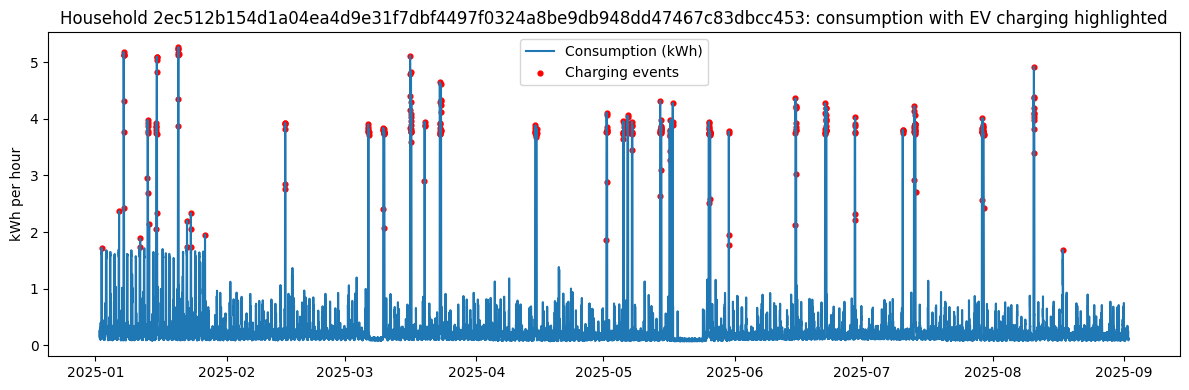

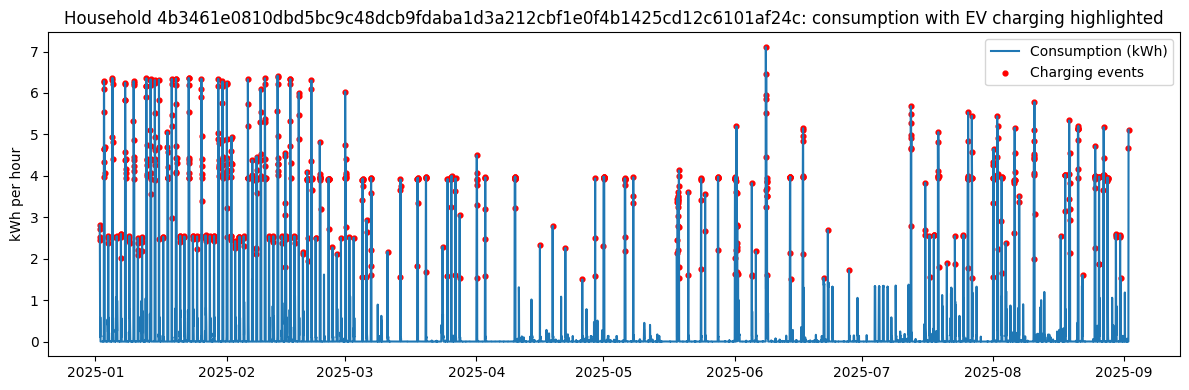

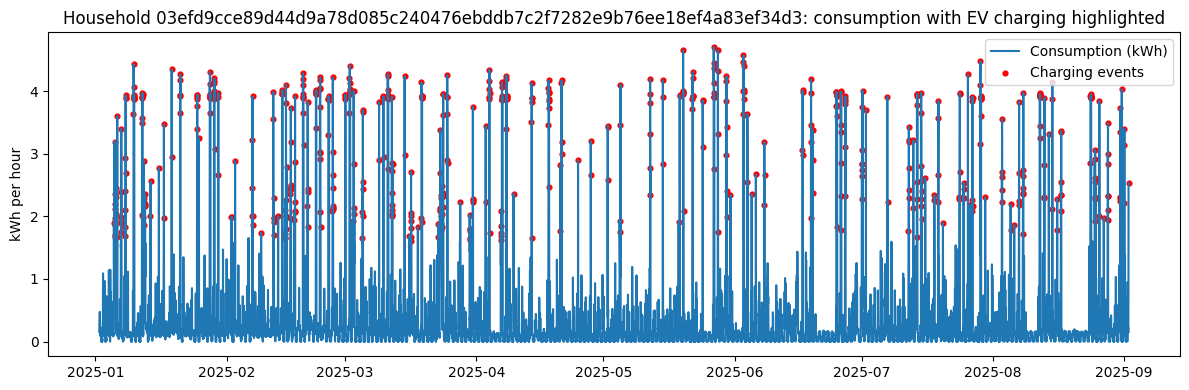

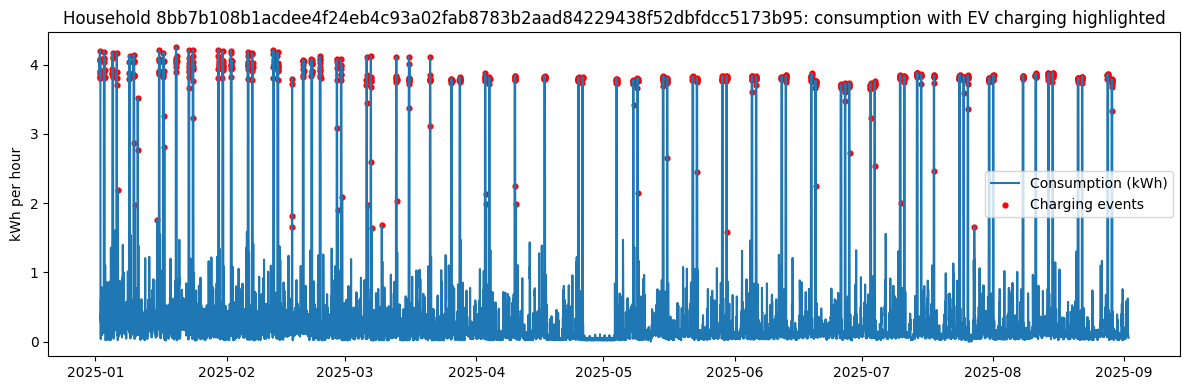

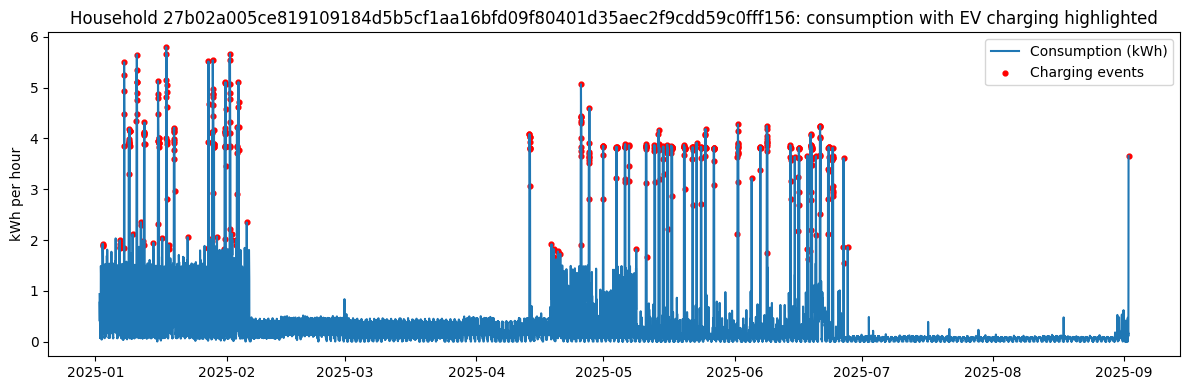

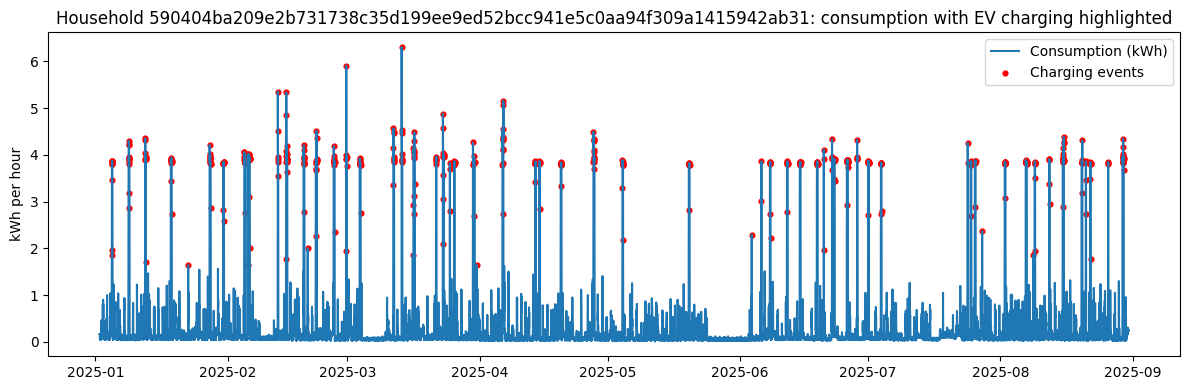

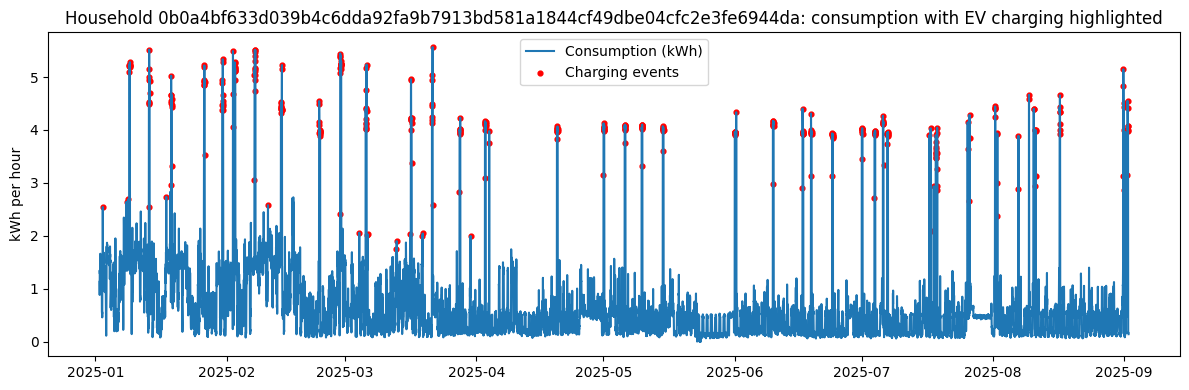

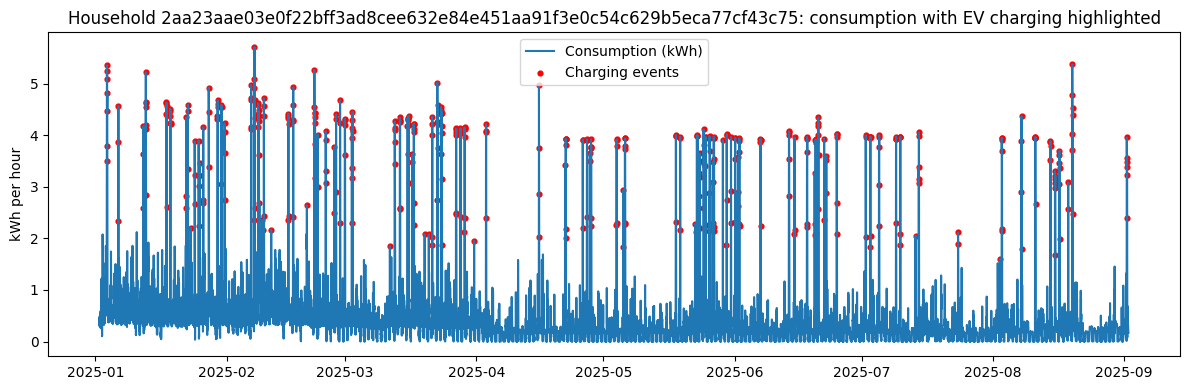

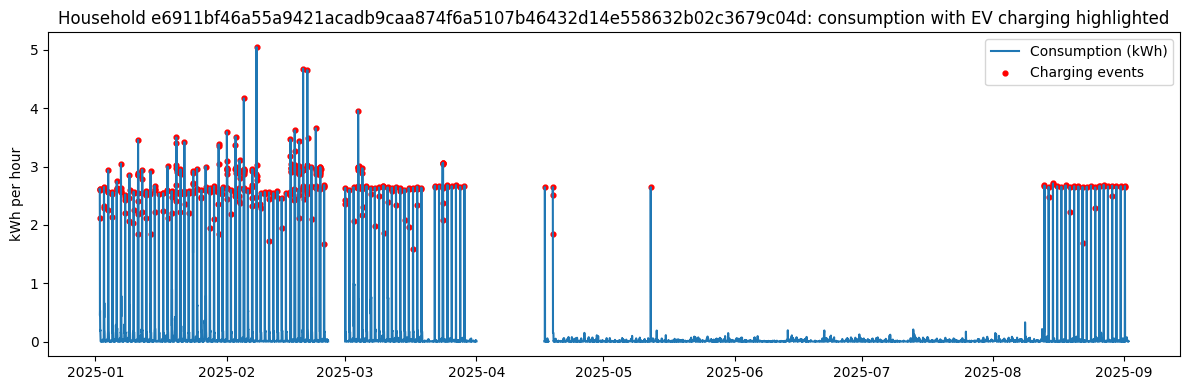

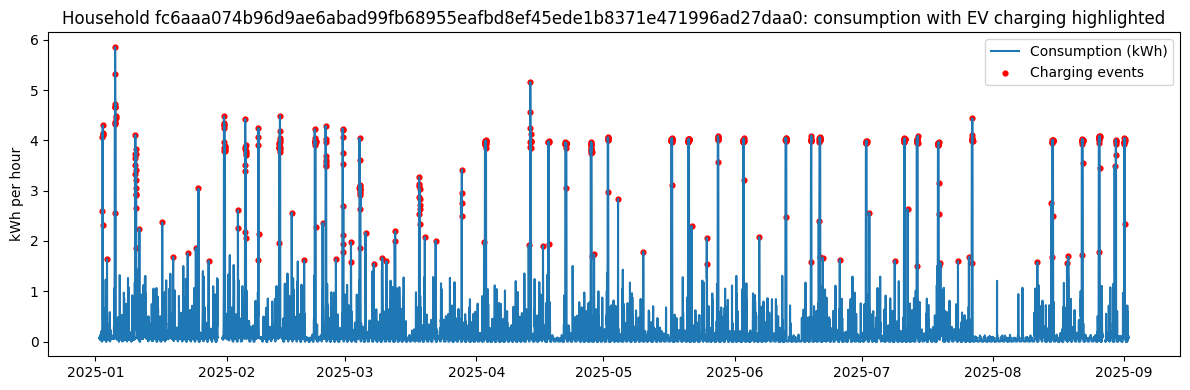

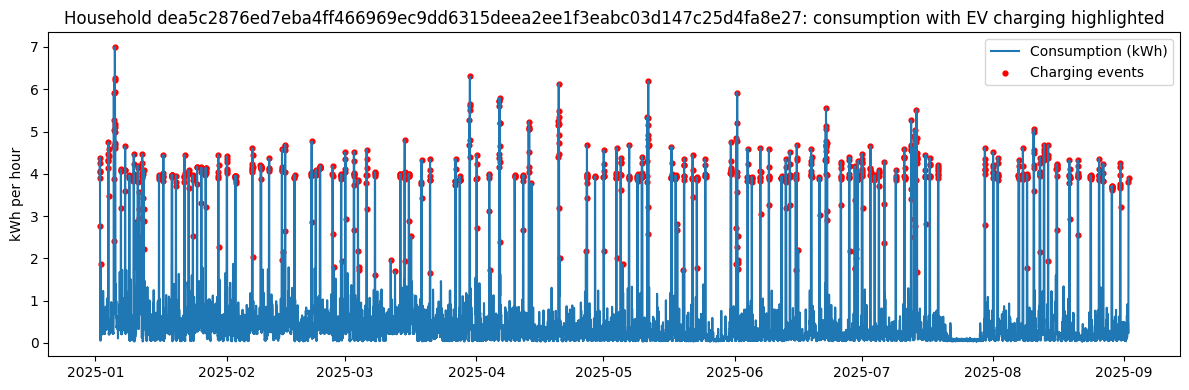

In [24]:
# example
for client in list_no_ev:
    plot_client_with_charging(df_flagged_C, client)   # or "A" depending on your labels


# Survival models

## Gap-time model

### Control

In [80]:
episodes = gen_df_events(df_flagged_C)
episodes

household,episode_id,start_ts,end_ts
str,i64,datetime[μs],datetime[μs]
"""03efd9cce89d44d9a78d085c240476…",0,2025-01-05 12:30:00,2025-01-05 14:00:00
"""03efd9cce89d44d9a78d085c240476…",1,2025-01-05 16:30:00,2025-01-05 20:00:00
"""03efd9cce89d44d9a78d085c240476…",2,2025-01-06 04:00:00,2025-01-06 04:30:00
"""03efd9cce89d44d9a78d085c240476…",3,2025-01-07 01:30:00,2025-01-07 04:30:00
"""03efd9cce89d44d9a78d085c240476…",4,2025-01-08 01:00:00,2025-01-08 05:00:00
…,…,…,…
"""fff1cfde616f1b03a9b23a1d5385bb…",27,2025-07-05 00:00:00,2025-07-05 05:00:00
"""fff1cfde616f1b03a9b23a1d5385bb…",28,2025-07-06 00:00:00,2025-07-06 01:30:00
"""fff1cfde616f1b03a9b23a1d5385bb…",29,2025-07-11 00:00:00,2025-07-11 03:00:00


In [81]:
gap_times = calculate_gaps(episodes)
gap_times

household,start_ts,end_ts,next_start,gap_hours_till_next_charge
str,datetime[μs],datetime[μs],datetime[μs],f64
"""03efd9cce89d44d9a78d085c240476…",2025-01-05 12:30:00,2025-01-05 14:00:00,2025-01-05 16:30:00,2.5
"""03efd9cce89d44d9a78d085c240476…",2025-01-05 16:30:00,2025-01-05 20:00:00,2025-01-06 04:00:00,8.0
"""03efd9cce89d44d9a78d085c240476…",2025-01-06 04:00:00,2025-01-06 04:30:00,2025-01-07 01:30:00,21.0
"""03efd9cce89d44d9a78d085c240476…",2025-01-07 01:30:00,2025-01-07 04:30:00,2025-01-08 01:00:00,20.5
"""03efd9cce89d44d9a78d085c240476…",2025-01-08 01:00:00,2025-01-08 05:00:00,2025-01-10 00:00:00,43.0
…,…,…,…,…
"""fff1cfde616f1b03a9b23a1d5385bb…",2025-06-22 00:00:00,2025-06-22 02:30:00,2025-07-05 00:00:00,309.5
"""fff1cfde616f1b03a9b23a1d5385bb…",2025-07-05 00:00:00,2025-07-05 05:00:00,2025-07-06 00:00:00,19.0
"""fff1cfde616f1b03a9b23a1d5385bb…",2025-07-06 00:00:00,2025-07-06 01:30:00,2025-07-11 00:00:00,118.5


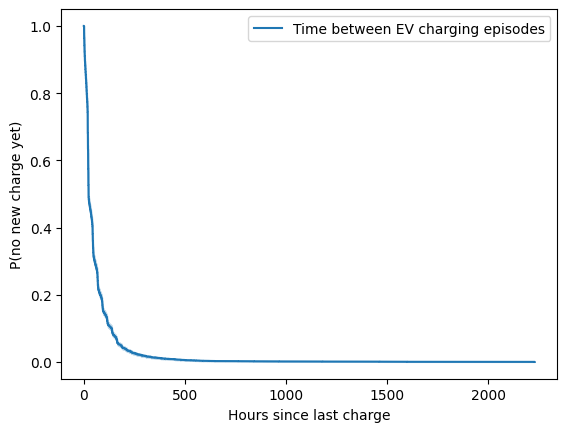

In [90]:
# How long after a charge does the next charge happen?

kmf = ll.KaplanMeierFitter()
kmf.fit(gap_times["gap_hours_till_next_charge"], label="Time between EV charging episodes")
kmf.plot_survival_function()

plt.xlabel("Hours since last charge")
plt.ylabel("P(no new charge yet)")
plt.show()

#Steep drop = frequent charging

### Intervention

In [85]:
episodes_I = gen_df_events(df_flagged_I)
gap_times_I = calculate_gaps(episodes_I)
gap_times_I

household,start_ts,end_ts,next_start,gap_hours_till_next_charge
str,datetime[μs],datetime[μs],datetime[μs],f64
"""03b289ae00b591df507da634086045…",2025-01-02 00:00:00,2025-01-02 03:30:00,2025-01-04 00:00:00,44.5
"""03b289ae00b591df507da634086045…",2025-01-04 00:00:00,2025-01-04 05:00:00,2025-01-06 00:00:00,43.0
"""03b289ae00b591df507da634086045…",2025-01-06 00:00:00,2025-01-06 05:00:00,2025-01-07 20:30:00,39.5
"""03b289ae00b591df507da634086045…",2025-01-07 20:30:00,2025-01-07 21:00:00,2025-01-08 00:00:00,3.0
"""03b289ae00b591df507da634086045…",2025-01-08 00:00:00,2025-01-08 04:00:00,2025-01-10 00:00:00,44.0
…,…,…,…,…
"""fe18b46b416a7f24cedeac9604de9b…",2025-08-12 00:00:00,2025-08-12 03:00:00,2025-08-13 00:00:00,21.0
"""fe18b46b416a7f24cedeac9604de9b…",2025-08-13 00:00:00,2025-08-13 05:00:00,2025-08-18 00:00:00,115.0
"""fe18b46b416a7f24cedeac9604de9b…",2025-08-18 00:00:00,2025-08-18 05:00:00,2025-08-24 00:00:00,139.0


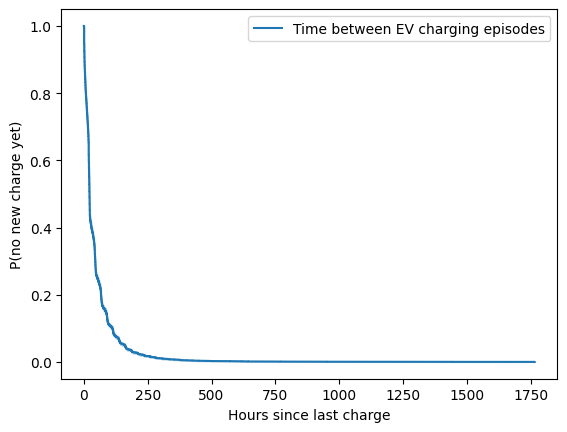

In [88]:
# How long after a charge does the next charge happen?

kmf = ll.KaplanMeierFitter()
kmf.fit(gap_times_I["gap_hours_till_next_charge"], label="Time between EV charging episodes")
kmf.plot_survival_function()

plt.xlabel("Hours since last charge")
plt.ylabel("P(no new charge yet)")
plt.show()

#Steep drop = frequent charging

## Andersen–Gill Cox model

household,start,stop,event
str,datetime[μs],datetime[μs],i8
"""03efd9cce89d44d9a78d085c240476…",2025-01-02 00:00:00,2025-01-02 00:30:00,0
"""03efd9cce89d44d9a78d085c240476…",2025-01-02 00:30:00,2025-01-02 01:00:00,0
"""03efd9cce89d44d9a78d085c240476…",2025-01-02 01:00:00,2025-01-02 01:30:00,0
"""03efd9cce89d44d9a78d085c240476…",2025-01-02 01:30:00,2025-01-02 02:00:00,0
"""03efd9cce89d44d9a78d085c240476…",2025-01-02 02:00:00,2025-01-02 02:30:00,0
…,…,…,…
"""fff1cfde616f1b03a9b23a1d5385bb…",2025-09-01 22:30:00,2025-09-01 23:00:00,0
"""fff1cfde616f1b03a9b23a1d5385bb…",2025-09-01 23:00:00,2025-09-01 23:30:00,0
"""fff1cfde616f1b03a9b23a1d5385bb…",2025-09-01 23:30:00,2025-09-02 00:00:00,0


In [ ]:
# What factors increase charging rate over time?

#Andersen–Gill Cox model: each household as a process over time

# cph = ll.CoxPHFitter()
# cph.fit(
#     df_cp.to_pandas(),
#     duration_col="duration",
#     event_col="event",
#     entry_col="start_t",
#     cluster_col="household"   
# )

# cph.print_summary()